# How much can we trust the confidence of a small LLM?

**Objective:** measure if the probabilities that an open-weight LLM gives to its answers are calibrated, that is, if the questions answered with 70% confidence are correct 70% of the time. We use two small models of the Qwen2.5 family (0.5B and 1.5B parameters, both instruct) on multiple choice questions of MMLU, we calculate the calibration error (ECE), we fix it with temperature scaling and we look at what we win if the model only answers when it is confident (selective prediction). At the end we compare the probability of the tokens with the confidence that the model says in words.

This matters in production: if a model classifies a claim or a client email, the confidence is what decides if a human has to review it.

**Data:** MMLU (Hendrycks et al., 2021), 57 subjects from high school to professional level. We take 1.000 random questions of the test set for the evaluation and 500 questions of the validation set to fit the temperature.

Libraries of the project: `torch`, `transformers`, `pandas`, `numpy`, `scipy`, `matplotlib` and `seaborn`. Everything runs on CPU.

## Part 1. Libraries and data

In [1]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer, AutoModelForCausalLM

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
torch.manual_seed(42)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
url = "hf://datasets/cais/mmlu/all/"
test = pd.read_parquet(url + "test-00000-of-00001.parquet").sample(1000, random_state=42).reset_index(drop=True)
val = pd.read_parquet(url + "validation-00000-of-00001.parquet").sample(500, random_state=42).reset_index(drop=True)
print("Test:", test.shape, "| Validation:", val.shape)
print("Subjects in test:", test["subject"].nunique())
test.head()

Test: (1000, 4) | Validation: (500, 4)
Subjects in test: 57


,question,subject,choices,answer
0,If a psychologist acts as both a fact witness ...,professional_psychology,"[unethically by accepting dual roles., ethical...",2
1,In what ways does the perspective on terrorism...,security_studies,"[Within the disease prescription, reform packa...",3
2,George was charged with the murder of a well- ...,professional_law,"[hearsay., irrelevant., opinion testimony., se...",1
3,Can countries rely on their domestic law as an...,international_law,[Domestic law always prevails over internation...,2
4,A 30-year-old nulliparous female presents to t...,professional_medicine,"[adjustment disorder with depressed mood, bipo...",0


Every question has 4 options and `answer` is the position of the correct one (0 = A, 1 = B...). A model that answers at random gets 25%.

## Part 2. Confidence from the logits

We do not let the model generate text. We give it the question with the chat template and we read the logits of the next token only for the 4 letters A, B, C and D. With a softmax over these 4 logits we get a probability for each option: the answer is the letter with the highest probability and the confidence is that probability. We keep the logits because later we need them to change the temperature.

In [3]:
def prompt(r):
    opciones = "\n".join(f"{l}. {c}" for l, c in zip("ABCD", r["choices"]))
    texto = f"Answer the following multiple choice question about {r['subject'].replace('_', ' ')} with the letter of the correct option only.\n\n{r['question']}\n{opciones}"
    return [{"role": "user", "content": texto}]

def letter_logits(nombre, data, batch=8):
    tok = AutoTokenizer.from_pretrained(nombre)
    tok.padding_side = "left"
    model = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float32).eval()
    ids_letras = [tok.encode(l)[0] for l in "ABCD"]
    textos = [tok.apply_chat_template(prompt(r), tokenize=False, add_generation_prompt=True) for _, r in data.iterrows()]
    # we sort the questions by length so every batch has questions of similar size and less padding
    orden = np.argsort([len(t) for t in textos])
    out = np.zeros((len(textos), 4), dtype=np.float32)
    for i in range(0, len(textos), batch):
        idx = orden[i:i + batch]
        x = tok([textos[j] for j in idx], return_tensors="pt", padding=True)
        with torch.no_grad():
            logits = model(**x).logits[:, -1, :]
        out[idx] = logits[:, ids_letras].numpy()
    return out

modelos = {"Qwen2.5-0.5B": "Qwen/Qwen2.5-0.5B-Instruct", "Qwen2.5-1.5B": "Qwen/Qwen2.5-1.5B-Instruct"}
logits = {}
for corto, nombre in modelos.items():
    for parte, data in [("test", test), ("val", val)]:
        ruta = f"data/logits_{corto}_{parte}.npy"
        if not os.path.exists(ruta):
            t = time.time()
            np.save(ruta, letter_logits(nombre, data))
            print(corto, parte, "done in", round((time.time() - t) / 60, 1), "min")
        logits[(corto, parte)] = np.load(ruta)
print("Shape of the logits:", logits[("Qwen2.5-0.5B", "test")].shape)

Qwen2.5-1.5B test done in 121.3 min


Qwen2.5-1.5B val done in 49.8 min
Shape of the logits: (1000, 4)


## Part 3. Accuracy

In [4]:
def softmax(z, T=1.0):
    z = z / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

y_test, y_val = test["answer"].values, val["answer"].values
res = {}
for corto in modelos:
    p = softmax(logits[(corto, "test")])
    res[corto] = pd.DataFrame({"subject": test["subject"], "pred": p.argmax(1), "conf": p.max(1),
                               "correct": (p.argmax(1) == y_test).astype(int)})
    print(corto, "accuracy:", round(res[corto]["correct"].mean(), 4))

Qwen2.5-0.5B accuracy: 0.36
Qwen2.5-1.5B accuracy: 0.579


The 1.5B model answers well many more questions than the 0.5B. Both are far from the big models (more than 80% in MMLU) but far above the 25% of random answers.

In [5]:
por_materia = pd.DataFrame({c: res[c].groupby("subject")["correct"].mean() for c in modelos})
por_materia["questions"] = res["Qwen2.5-0.5B"].groupby("subject").size()
por_materia = por_materia[por_materia["questions"] >= 15].sort_values("Qwen2.5-1.5B")
pd.concat([por_materia.head(5), por_materia.tail(5)]).round(2)

,Qwen2.5-0.5B,Qwen2.5-1.5B,questions
subject,,,
moral_scenarios,0.16,0.25,76
professional_accounting,0.24,0.29,21
high_school_physics,0.29,0.35,17
high_school_chemistry,0.24,0.35,17
high_school_macroeconomics,0.39,0.39,31
conceptual_physics,0.33,0.78,18
high_school_european_history,0.20,0.80,15
high_school_government_and_politics,0.53,0.80,15
sociology,0.58,0.84,19


## Part 4. Calibration: reliability diagram and ECE

We put the questions in 10 bins by confidence and in each bin we compare the average confidence with the accuracy. If the model is calibrated the points are on the diagonal. The Expected Calibration Error (ECE) is the weighted average of |accuracy - confidence| over the bins. We also calculate the Brier score and the negative log-likelihood (NLL) of the correct answer, which are proper scoring rules.

In [6]:
def ece(conf, correct, bins=10):
    cortes = np.linspace(0.25, 1, bins + 1)
    idx = np.clip(np.digitize(conf, cortes) - 1, 0, bins - 1)
    total = 0
    for b in range(bins):
        m = idx == b
        if m.sum() > 0:
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total

def metricas(z, y, T=1.0):
    p = softmax(z, T)
    conf, correct = p.max(1), (p.argmax(1) == y).astype(float)
    onehot = np.eye(4)[y]
    return {"accuracy": correct.mean(), "avg confidence": conf.mean(), "ECE": ece(conf, correct),
            "Brier": ((p - onehot) ** 2).sum(1).mean(), "NLL": -np.log(p[np.arange(len(y)), y]).mean()}

tabla = pd.DataFrame({c: metricas(logits[(c, "test")], y_test) for c in modelos}).T
tabla.round(4)

,accuracy,avg confidence,ECE,Brier,NLL
Qwen2.5-0.5B,0.360,0.5621,0.2021,0.7748,1.4558
Qwen2.5-1.5B,0.579,0.8021,0.2242,0.6314,1.4437


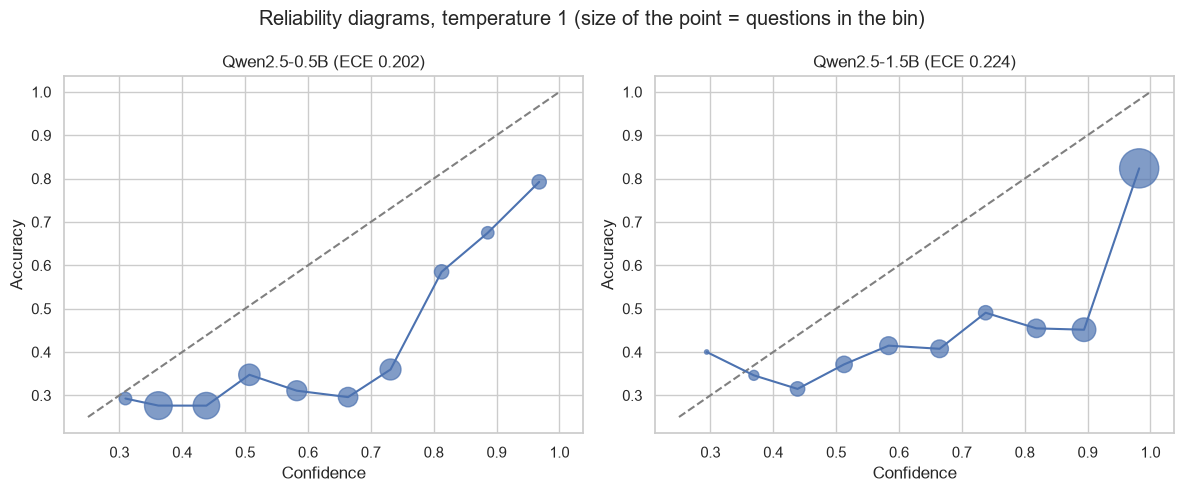

In [7]:
def reliability(ax, conf, correct, titulo, bins=10):
    cortes = np.linspace(0.25, 1, bins + 1)
    idx = np.clip(np.digitize(conf, cortes) - 1, 0, bins - 1)
    d = pd.DataFrame({"bin": idx, "conf": conf, "correct": correct}).groupby("bin").agg(
        conf=("conf", "mean"), acc=("correct", "mean"), n=("conf", "size"))
    ax.plot([0.25, 1], [0.25, 1], ls="--", color="grey")
    ax.scatter(d["conf"], d["acc"], s=d["n"] * 2, alpha=0.7)
    ax.plot(d["conf"], d["acc"], marker="")
    ax.set_title(titulo)
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Accuracy")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, c in zip(axes, modelos):
    reliability(ax, res[c]["conf"].values, res[c]["correct"].values, f"{c} (ECE {tabla.loc[c, 'ECE']:.3f})")
plt.suptitle("Reliability diagrams, temperature 1 (size of the point = questions in the bin)")
plt.tight_layout()
plt.savefig("figures/reliability_raw.png", bbox_inches="tight")
plt.show()

Both models are overconfident: almost all the points are under the diagonal. The 1.5B model is the clearest case. It gives more than 95% of confidence to 35% of the questions, but only 85% of them are correct, and when its confidence is between 60% and 90% it is right only 43% of the time. The accuracy of the 1.5B is much better than the one of the 0.5B, but its ECE is a little worse (0.224 vs 0.202): a bigger model is not automatically a better calibrated model.

## Part 5. Temperature scaling

Temperature scaling (Guo et al., 2017) divides the logits by a number T before the softmax. With T > 1 the probabilities are flatter (less confident) and with T < 1 they are sharper. It does not change the answer, only the confidence, so the accuracy stays the same. We choose T minimising the NLL in the validation set and we apply it to the test set, so the test set is never used to fit anything.

In [8]:
temps = {}
for c in modelos:
    f = lambda T: metricas(logits[(c, "val")], y_val, T)["NLL"]
    temps[c] = minimize_scalar(f, bounds=(0.05, 20), method="bounded").x
    print(c, "optimal temperature:", round(temps[c], 3))

tabla_t = pd.DataFrame({c: metricas(logits[(c, "test")], y_test, temps[c]) for c in modelos}).T
comparacion = pd.concat([tabla[["ECE", "Brier", "NLL"]].add_suffix(" T=1"), tabla_t[["ECE", "Brier", "NLL"]].add_suffix(" fitted T")], axis=1)
comparacion.round(4)

Qwen2.5-0.5B optimal temperature: 2.155
Qwen2.5-1.5B optimal temperature: 2.579


,ECE T=1,Brier T=1,NLL T=1,ECE fitted T,Brier fitted T,NLL fitted T
Qwen2.5-0.5B,0.2021,0.7748,1.4558,0.0670,0.7085,1.3126
Qwen2.5-1.5B,0.2242,0.6314,1.4437,0.0533,0.5455,1.0466


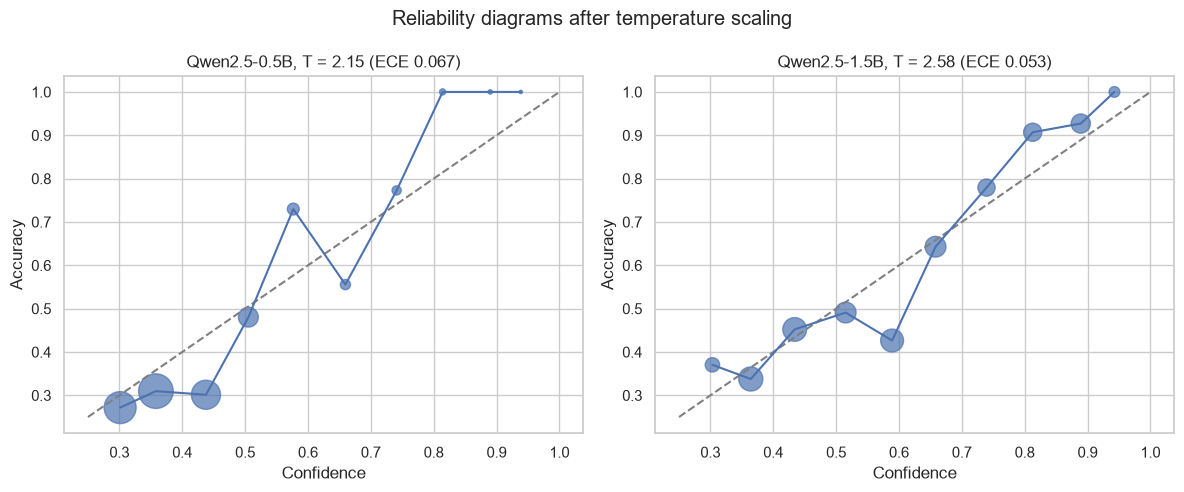

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, c in zip(axes, modelos):
    p = softmax(logits[(c, "test")], temps[c])
    reliability(ax, p.max(1), (p.argmax(1) == y_test).astype(float), f"{c}, T = {temps[c]:.2f} (ECE {tabla_t.loc[c, 'ECE']:.3f})")
plt.suptitle("Reliability diagrams after temperature scaling")
plt.tight_layout()
plt.savefig("figures/reliability_scaled.png", bbox_inches="tight")
plt.show()

The optimal temperature is above 2 for both models, so the original probabilities are much too sharp. With the temperature fitted in validation the ECE of the test set goes from 0.202 to 0.067 for the 0.5B and from 0.224 to 0.053 for the 1.5B, and the NLL of the 1.5B falls from 1.44 to 1.05. The answers are exactly the same, only the confidence changes. After the scaling the points of the 1.5B are close to the diagonal; the 0.5B still has bins with very few questions that move a lot.

Let's check how the ECE of the test set moves with T, to see if the T fitted in validation is close to the best possible one.

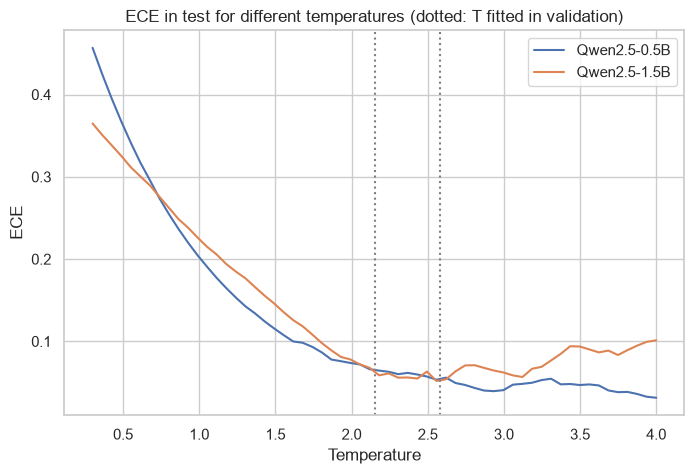

In [10]:
ts = np.linspace(0.3, 4, 60)
plt.figure(figsize=(8, 5))
for c in modelos:
    plt.plot(ts, [metricas(logits[(c, "test")], y_test, t)["ECE"] for t in ts], label=c)
    plt.axvline(temps[c], ls=":", color="grey")
plt.title("ECE in test for different temperatures (dotted: T fitted in validation)")
plt.xlabel("Temperature")
plt.ylabel("ECE")
plt.legend()
plt.show()

## Part 6. Selective prediction

If the confidence is good for ranking, the model can answer only the questions where it is more confident and send the rest to a human. The risk-coverage curve shows the accuracy of the answered questions when we keep the x% with highest confidence. We compare it with an "oracle" that knows which ones are correct, which is the best possible ranking.

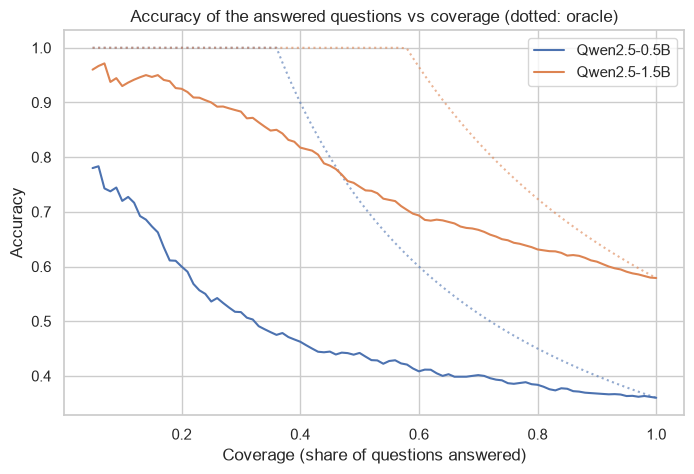

In [11]:
plt.figure(figsize=(8, 5))
cobertura = np.arange(0.05, 1.0001, 0.01)
for c in modelos:
    orden = res[c].sort_values("conf", ascending=False)["correct"].values
    acc = [orden[:max(1, int(k * len(orden)))].mean() for k in cobertura]
    plt.plot(cobertura, acc, label=c)
    oraculo = np.sort(res[c]["correct"].values)[::-1]
    plt.plot(cobertura, [oraculo[:max(1, int(k * len(oraculo)))].mean() for k in cobertura], ls=":", color=plt.gca().lines[-1].get_color(), alpha=0.6)
plt.title("Accuracy of the answered questions vs coverage (dotted: oracle)")
plt.xlabel("Coverage (share of questions answered)")
plt.ylabel("Accuracy")
plt.legend()
plt.savefig("figures/selective_prediction.png", bbox_inches="tight")
plt.show()

In [12]:

filas = []
for c in modelos:
    r = res[c].sort_values("conf", ascending=False)
    for k in [0.25, 0.5, 0.75, 1.0]:
        filas.append([c, k, r["correct"].values[:int(k * len(r))].mean()])
sel = pd.DataFrame(filas, columns=["model", "coverage", "accuracy"]).pivot(index="coverage", columns="model", values="accuracy")
print("AUROC of the confidence to separate correct and wrong answers:")
for c in modelos:
    print(" ", c, round(roc_auc_score(res[c]["correct"], res[c]["conf"]), 4))
sel.round(3)

AUROC of the confidence to separate correct and wrong answers:


  Qwen2.5-0.5B 0.6284
  Qwen2.5-1.5B 0.7387


model,Qwen2.5-0.5B,Qwen2.5-1.5B
coverage,,
0.25,0.536,0.900
0.50,0.442,0.746
0.75,0.387,0.648
1.00,0.360,0.579


The temperature does not change the order of the questions, so this curve is the same before and after the calibration. The ranking is useful: if the 1.5B model answers only the 25% of questions where it is more confident, the accuracy is 90% instead of 58%, and with half of the questions it is 75%. The AUROC of 0.74 says that the confidence separates correct and wrong answers, but it is still far from the oracle. For the 0.5B the curve falls very fast: its confidence is a weak signal (AUROC 0.63).

## Part 7. Verbalized confidence

Many applications do not have access to the logits (closed APIs) and ask the model to say its confidence in words. We ask the 1.5B model to answer and to give a confidence between 0 and 100, for 300 questions of the test set, and we compare it with the probability of the tokens for the same questions.

In [13]:

ruta = "data/verbalized_Qwen2.5-1.5B.csv"
if not os.path.exists(ruta):
    nombre = modelos["Qwen2.5-1.5B"]
    tok = AutoTokenizer.from_pretrained(nombre)
    model = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float32).eval()
    filas = []
    for i, r in test.head(300).iterrows():
        m = prompt(r)
        m[0]["content"] = m[0]["content"].replace("with the letter of the correct option only.",
            "Reply in the format 'Answer: <letter>, Confidence: <number from 0 to 100>' where the confidence is the probability that your answer is correct.")
        x = tok.apply_chat_template(m, return_tensors="pt", add_generation_prompt=True, return_dict=True)
        with torch.no_grad():
            g = model.generate(**x, max_new_tokens=20, do_sample=False)
        filas.append([i, tok.decode(g[0, x["input_ids"].shape[1]:], skip_special_tokens=True)])
    pd.DataFrame(filas, columns=["i", "text"]).to_csv(ruta, index=False)

verb = pd.read_csv(ruta)
verb["letter"] = verb["text"].str.extract(r"Answer:\s*([ABCD])")[0]
verb["said_conf"] = pd.to_numeric(verb["text"].str.extract(r"Confidence:\s*(\d+)")[0], errors="coerce") / 100
verb["correct"] = (verb["letter"].map({"A": 0, "B": 1, "C": 2, "D": 3}) == y_test[verb["i"]]).astype(int)
verb["token_conf"] = res["Qwen2.5-1.5B"]["conf"].values[verb["i"]]
print("Answers with the right format:", verb["said_conf"].notna().mean())
print("Accuracy:", round(verb["correct"].mean(), 4))
print("Average verbalized confidence:", round(verb["said_conf"].mean(), 4))
verb["said_conf"].value_counts().head(8)

Answers with the right format: 0.75
Accuracy: 0.54
Average verbalized confidence: 0.8675


said_conf
0.85    154
0.95     44
1.00     17
0.90      3
0.09      2
0.75      2
0.00      1
0.60      1
Name: count, dtype: int64

ECE verbalized: 0.2544
AUROC verbalized: 0.5475
AUROC token probability (same questions): 0.7465


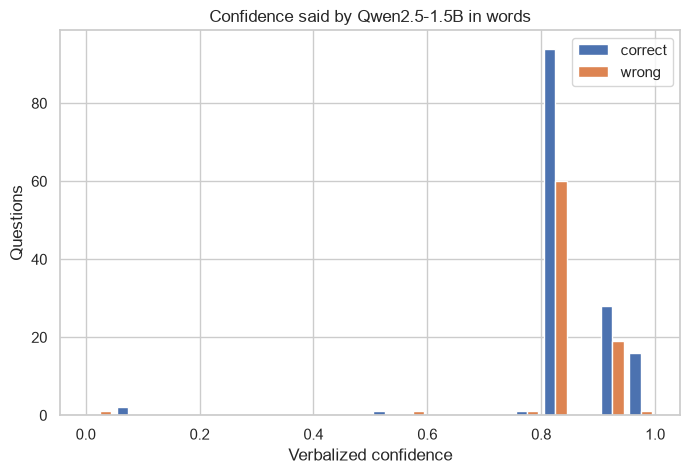

In [14]:
v = verb.dropna(subset=["said_conf"])
print("ECE verbalized:", round(ece(v["said_conf"].clip(0.25, 1).values, v["correct"].values), 4))
print("AUROC verbalized:", round(roc_auc_score(v["correct"], v["said_conf"]), 4))
print("AUROC token probability (same questions):", round(roc_auc_score(v["correct"], v["token_conf"]), 4))

plt.figure(figsize=(8, 5))
plt.hist([v.loc[v["correct"] == 1, "said_conf"], v.loc[v["correct"] == 0, "said_conf"]], bins=np.linspace(0, 1, 21), label=["correct", "wrong"])
plt.title("Confidence said by Qwen2.5-1.5B in words")
plt.xlabel("Verbalized confidence")
plt.ylabel("Questions")
plt.legend()
plt.savefig("figures/verbalized_confidence.png", bbox_inches="tight")
plt.show()

The confidence in words is almost useless. A quarter of the answers do not follow the format, and when they do the model says 85% most of the time, whatever the question: the average is 87% with an accuracy of 54% (counting the answers with a wrong format as errors), and the ECE is 0.25. Worse, it does not rank: the AUROC is 0.55, close to random, against 0.75 for the probability of the tokens on the same questions. When we have access to the logits it is much better to use them.

## Part 8. Conclusions

- The two Qwen2.5 models are overconfident on MMLU, with an ECE above 0.20. The 1.5B gives more than 95% of confidence to a third of the questions and is wrong in 15% of them.
- One parameter fixes most of the problem: temperature scaling fitted on 500 validation questions reduces the ECE of the test set by 67% (0.5B) and 76% (1.5B) without changing any answer.
- The confidence ranks the questions well enough to use it for routing: answering only the most confident half, the 1.5B goes from 58% to 75% of accuracy. This is how we would decide which cases go to a human.
- The confidence that the model writes in words is not calibrated and almost does not rank (AUROC 0.55 vs 0.75 with the logits).
- Limits: 1.000 test questions (the bins with few questions are noisy), two small models and only multiple choice. For open answers we would need other methods, like the agreement between several samples or a second model as a verifier.